# Robustness of the spectral result

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seafloor as sf

lon, lat, z, ship, dx, dy = sf.load_clean()
clusters = np.load(sf.DATA_DIR / "clusters.npy")
plains = clusters == 1
rng = np.random.default_rng(0)

def boot_hp(wl, A, B, n=500):
    vals = [sf.half_power_wavelength(wl, A[rng.integers(0, len(A), len(A))], B[rng.integers(0, len(B), len(B))]) for _ in range(n)]
    return np.nanpercentile(vals, [2.5, 97.5])

In [2]:
variants = {
    "original (N=64, detrend, Hann)": dict(),
    "block 48 (~23 km)":               dict(N=48),
    "block 96 (~46 km)":               dict(N=96),
    "no detrend":                      dict(detrend=False),
    "no window":                       dict(window=False),
    "plains blocks only":              dict(extra_mask=plains),
}
results = {}
for name, kw in variants.items():
    wl, A, B, cen = sf.block_spectra(z, ship, dx, dy, **kw)
    if len(A) < 10 or len(B) < 10:
        print(f"{name:32s} too few blocks ({len(A)} ship, {len(B)} sat)"); continue
    hp = sf.half_power_wavelength(wl, A, B); lo, hi = boot_hp(wl, A, B)
    results[name] = (hp, lo, hi, len(A), len(B), wl, np.exp(B.mean(0) - A.mean(0)))
    print(f"{name:32s} half-power ≈ {hp:4.1f} km  (95%: {lo:4.1f}–{hi:4.1f})   blocks ship {len(A)}, sat {len(B)}")

original (N=64, detrend, Hann)   half-power ≈  4.0 km  (95%:  2.7– 8.0)   blocks ship 191, sat 139


block 48 (~23 km)                half-power ≈  3.9 km  (95%:  2.9– 5.3)   blocks ship 412, sat 278
block 96 (~46 km)                half-power ≈  4.6 km  (95%:  2.5–19.8)   blocks ship 76, sat 46


no detrend                       half-power ≈  4.0 km  (95%:  2.7– 7.9)   blocks ship 191, sat 139
no window                        half-power ≈  nan km  (95%:  2.9–14.7)   blocks ship 191, sat 139


plains blocks only               half-power ≈  2.3 km  (95%:  1.3– 3.3)   blocks ship 98, sat 98


In [3]:
wl, A, B, cen = sf.block_spectra(z, ship, dx, dy)
dA = np.array([np.nanmedian(z[i-32:i+32, j-32:j+32]) for i, j in cen[True]])
dB = np.array([np.nanmedian(z[i-32:i+32, j-32:j+32]) for i, j in cen[False]])
nearest = np.array([np.argmin(np.abs(dA - x)) for x in dB])
A_matched = A[nearest]
print(f"Median depth: ship blocks {np.median(dA):,.0f} m, satellite blocks {np.median(dB):,.0f} m, matched ship {np.median(dA[nearest]):,.0f} m")
hp = sf.half_power_wavelength(wl, A_matched, B); lo, hi = boot_hp(wl, A_matched, B)
results["depth-matched"] = (hp, lo, hi, len(np.unique(nearest)), len(B), wl, np.exp(B.mean(0) - A_matched.mean(0)))
print(f"{'depth-matched':32s} half-power ≈ {hp:4.1f} km  (95%: {lo:4.1f}–{hi:4.1f})")

Median depth: ship blocks -4,460 m, satellite blocks -4,636 m, matched ship -4,626 m
depth-matched                    half-power ≈  2.7 km  (95%:  1.6– 4.6)


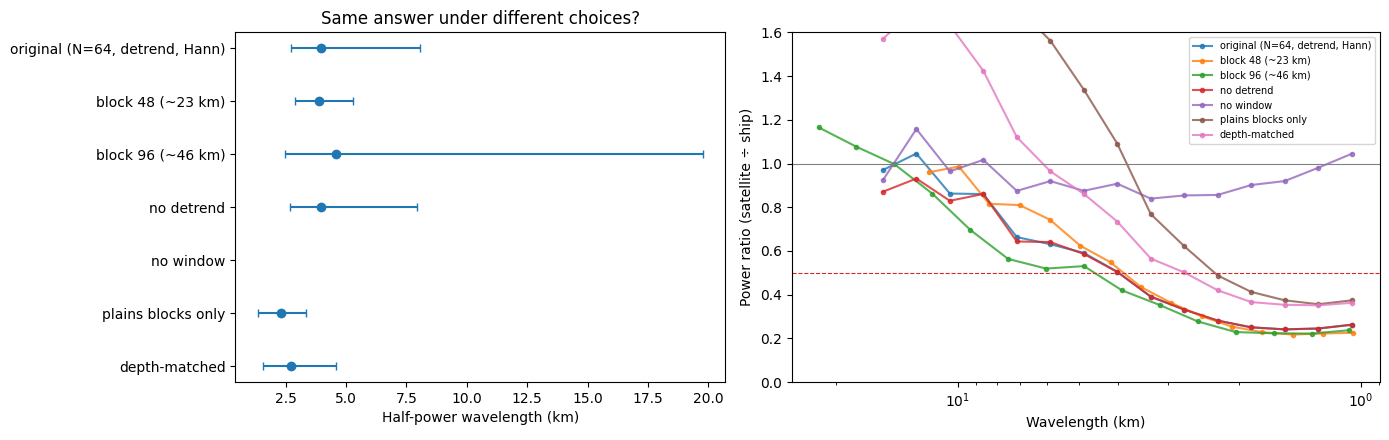

In [4]:
names = list(results)
hp = np.array([results[n][0] for n in names]); lo = np.array([results[n][1] for n in names]); hi = np.array([results[n][2] for n in names])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw=dict(width_ratios=[1, 1.2]))
y = np.arange(len(names))
axes[0].errorbar(hp, y, xerr=[hp - lo, hi - hp], fmt="o", capsize=3)
axes[0].set_yticks(y, names); axes[0].invert_yaxis()
axes[0].set(xlabel="Half-power wavelength (km)", title="Same answer under different choices?")
for n in names:
    axes[1].semilogx(results[n][5], results[n][6], ".-", label=n, alpha=0.8)
axes[1].axhline(1, c="gray", lw=0.8); axes[1].axhline(0.5, c="tab:red", ls="--", lw=0.8); axes[1].invert_xaxis()
axes[1].set(xlabel="Wavelength (km)", ylabel="Power ratio (satellite ÷ ship)", ylim=(0, 1.6)); axes[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "09_robustness.png", dpi=200); plt.show()

In [5]:
F = sf.compute_features(z, dx, dy); rough, depth, bpi_b = F[..., 2], F[..., 0], F[..., 4]
ok = ~np.isnan(F).any(-1)
def strat_ratio(band_m, n_bpi):
    db = np.floor(depth / band_m).astype(int)
    bb = np.digitize(bpi_b, np.nanpercentile(bpi_b[ok], np.linspace(0, 100, n_bpi + 1)[1:-1]))
    st = db * 100 + bb; rows = []
    for s in np.unique(st[ok]):
        m = ok & (st == s); a, b = rough[m & ship], rough[m & ~ship]
        if len(a) >= 500 and len(b) >= 500: rows.append((len(a) + len(b), np.median(b) / np.median(a)))
    rows = np.array(rows); return np.exp(np.average(np.log(rows[:, 1]), weights=rows[:, 0]))
strat_rows = []
for band in [250, 500, 1000]:
    for nb_ in [2, 3, 5]:
        strat_rows.append((band, nb_, strat_ratio(band, nb_)))
        print(f"depth bands {band:4d} m × {nb_} BPI groups → ratio {strat_rows[-1][2]:.2f}")
sr = np.array([r[2] for r in strat_rows])
print(f"\nRange across 9 stratification choices: {sr.min():.2f} – {sr.max():.2f}  (naive was 0.70)")

/tmp/ipykernel_638/4245124907.py:4: RuntimeWarning: invalid value encountered in cast
  db = np.floor(depth / band_m).astype(int)


depth bands  250 m × 2 BPI groups → ratio 0.88


depth bands  250 m × 3 BPI groups → ratio 0.89


depth bands  250 m × 5 BPI groups → ratio 0.93


depth bands  500 m × 2 BPI groups → ratio 0.89


depth bands  500 m × 3 BPI groups → ratio 0.89


depth bands  500 m × 5 BPI groups → ratio 0.92


depth bands 1000 m × 2 BPI groups → ratio 0.87


depth bands 1000 m × 3 BPI groups → ratio 0.88


depth bands 1000 m × 5 BPI groups → ratio 0.92

Range across 9 stratification choices: 0.87 – 0.93  (naive was 0.70)


In [6]:
print("KEY NUMBERS")
for n in names: print(f"  {n:32s} {results[n][0]:4.1f} km ({results[n][1]:.1f}–{results[n][2]:.1f})")
print(f"  Half-power wavelength range across variants: {np.nanmin(hp):.1f} – {np.nanmax(hp):.1f} km")
print(f"  Stratified roughness ratio across 9 choices: {sr.min():.2f} – {sr.max():.2f}")

KEY NUMBERS
  original (N=64, detrend, Hann)    4.0 km (2.7–8.0)
  block 48 (~23 km)                 3.9 km (2.9–5.3)
  block 96 (~46 km)                 4.6 km (2.5–19.8)
  no detrend                        4.0 km (2.7–7.9)
  no window                         nan km (2.9–14.7)
  plains blocks only                2.3 km (1.3–3.3)
  depth-matched                     2.7 km (1.6–4.6)
  Half-power wavelength range across variants: 2.3 – 4.6 km
  Stratified roughness ratio across 9 choices: 0.87 – 0.93
